# Oculus — Plain BCE CNN | Non-Ben Graham: balanced & imbalanced
Two new independent training runs using the non-Ben Graham `processed/` images. Both use the same CNN and plain BCE loss as the earlier Ben Graham experiments. The balanced run uses ordinary shuffled batches; the imbalanced run uses 19 non-DR and 13 DR images per batch with repeat-aware augmentation. Validation and test identities are unchanged. Thresholds are chosen on validation to target at least 90% sensitivity, then frozen for test evaluation.

**Kaggle setup:** Attach the `02-preprocessing` notebook output by `lohitashwamadhan`, enable a GPU accelerator, and run cells in order. Both runs train by default; do not re-run training merely to recover metrics. No non-Ben Graham results are available yet.

## 1. Imports and configuration

In [1]:
import os, random, math, json, zipfile, shutil, hashlib
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import transforms
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 32
PATIENCE = 5
MIN_AUROC_IMPROVEMENT = 0.0  # strict AUROC improvement resets patience
LR = 1e-3
WEIGHT_DECAY = 1e-4
TARGET_SENSITIVITY = 0.90
# No fixed epoch cap. External Kaggle runtime limits can still stop a run.
MAX_EPOCHS = None
NUM_WORKERS = 2
WORK_ROOT = Path('/kaggle/working/oculus_plain_bce_raw')
WORK_ROOT.mkdir(parents=True, exist_ok=True)
ROOT = Path('/kaggle/working/extracted_data')
IMAGE_ROOT = ROOT / 'processed'
PREPROCESSING_ZIP = Path('/kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/_output_.zip')
RUN_TRAINING = True
RUN_TEST = True
RUN_NAMES = ['run3_balanced_non_ben_graham', 'run4_imbalanced_non_ben_graham']
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert torch.cuda.is_available(), 'Enable GPU in Kaggle before running.'
print('Device:', device)


Device: cuda


## 2. Extract only non-Ben Graham images

In [2]:
assert PREPROCESSING_ZIP.is_file(), f'Attach preprocessing notebook output: {PREPROCESSING_ZIP}'
ROOT.mkdir(parents=True, exist_ok=True)
marker = ROOT / '.non_bg_extraction_complete'
required = [ROOT / 'manifest_v2.csv'] + [IMAGE_ROOT / s for s in ['train','val','test','unused']]
if not marker.exists() or not all(p.exists() for p in required):
    with zipfile.ZipFile(PREPROCESSING_ZIP) as z:
        members = [m for m in z.infolist() if m.filename == 'manifest_v2.csv' or m.filename.startswith('processed/')]
        assert any(m.filename == 'manifest_v2.csv' for m in members), 'Manifest missing from archive'
        assert any(m.filename.startswith('processed/') and not m.is_dir() for m in members), 'Non-BG images missing from archive'
        for m in members:
            if not (ROOT / m.filename).resolve().is_relative_to(ROOT.resolve()):
                raise ValueError(f'Unsafe ZIP path: {m.filename}')
            if ((m.external_attr >> 16) & 0o170000) == 0o120000:
                raise ValueError(f'Symlink in ZIP: {m.filename}')
        z.extractall(ROOT, members=members)
    assert all(p.exists() for p in required)
    marker.touch()
print('Non-Ben Graham dataset available:', IMAGE_ROOT)


Non-Ben Graham dataset available: /kaggle/working/extracted_data/processed


## 3. Reconstruct manifests and verify patient isolation

In [3]:
df = pd.read_csv(f"{ROOT}/manifest_v2.csv")

# Protect the current validation and test sets.
held_out = df[df["split"].isin(["val", "test"])].copy()
held_out_groups = set(held_out["group_id"].dropna())

# Existing balanced training dataset.
balanced_train = df[df["split"] == "train"].copy()

# Recover non-DR images removed by undersampling.
restored = df[
    (df["split"] == "unused")
    & (df["orig_split"] == "train")
    & (df["excluded_reason"] == "undersampled_no_DR")
    & (df["label"] == 0)
].copy()

# Exclude patient groups found in validation or test.
restored = restored[
    ~restored["group_id"].isin(held_out_groups)
].copy()

# Build the new imbalanced training dataset.
restored["split"] = "train"

imbalanced_train = pd.concat(
    [balanced_train, restored],
    ignore_index=True
)

# Keep each image's original storage folder.
imbalanced_train["storage_split"] = (
    ["train"] * len(balanced_train)
    + ["unused"] * len(restored)
)

# Create complete manifests, including unchanged validation/test.
balanced_full = df[
    df["split"].isin(["train", "val", "test"])
].copy()

balanced_full["storage_split"] = balanced_full["split"]

imbalanced_full = pd.concat(
    [imbalanced_train, held_out],
    ignore_index=True
)

imbalanced_full.loc[
    imbalanced_full["storage_split"].isna(),
    "storage_split"
] = imbalanced_full["split"]

# Point to the actual non-Ben Graham image files.
for frame in [balanced_full, imbalanced_full]:
    frame["processed_path"] = frame.apply(
        lambda row: os.path.join(
            ROOT,
            "processed",
            row["storage_split"],
            row["filename"]
        ),
        axis=1
    )

    assert frame["processed_path"].map(os.path.isfile).all(), \
        "Missing non-Ben Graham images!"

    assert frame["group_id"].notna().all(), \
        "Missing group IDs!"

    assert (
        frame.groupby("group_id")["split"].nunique().max()
        == 1
    ), "Patient group overlap detected!"

# Confirm the validation and test rows are unchanged.
for split in ["val", "test"]:
    a = balanced_full[balanced_full["split"] == split]
    b = imbalanced_full[imbalanced_full["split"] == split]

    cols = ["source", "filename", "group_id", "label"]
    assert a[cols].value_counts().sort_index().equals(
        b[cols].value_counts().sort_index()
    ), f"{split} sets do not match!"

# Save the manifests.
balanced_path = f"{ROOT}/balanced_raw_manifest.csv"
imbalanced_path = f"{ROOT}/imbalanced_raw_manifest.csv"

balanced_full.to_csv(balanced_path, index=False)
imbalanced_full.to_csv(imbalanced_path, index=False)

print("BALANCED TRAINING:")
print(balanced_full.query("split == 'train'")["label"].value_counts())

print("\nIMBALANCED TRAINING:")
print(imbalanced_full.query("split == 'train'")["label"].value_counts())

print("\nManifests saved successfully!")

# Use the explicitly reconstructed paths; never fall back to another image variant.
balanced = balanced_full.reset_index(drop=True).copy()
imbalanced = imbalanced_full.reset_index(drop=True).copy()
for title, frame, expected in [('Balanced', balanced, (15126,15161)), ('Imbalanced', imbalanced, (40672,15161))]:
    frame['image_path'] = frame['processed_path']
    assert frame['image_path'].str.startswith(str(IMAGE_ROOT) + '/').all()
    assert frame['label'].isin([0,1]).all()
    counts = pd.crosstab(frame['split'], frame['label'])
    assert tuple(counts.loc['train', [0,1]]) == expected
    assert tuple(counts.loc['val', [0,1]]) == (4892,1591)
    assert tuple(counts.loc['test', [0,1]]) == (4907,1584)
    print(title, '\n', counts)
    print('Group overlap:', frame.groupby('group_id')['split'].nunique().gt(1).sum())
    for split in ['val','test']:
        cols = ['source','filename','group_id','label']
        assert frame.loc[frame.split.eq(split), cols].value_counts().sort_index().equals(df.loc[df.split.eq(split), cols].value_counts().sort_index())
print('Validation/test identities verified; non-BG paths verified.')


BALANCED TRAINING:
label
1    15161
0    15126
Name: count, dtype: int64

IMBALANCED TRAINING:
label
0    40672
1    15161
Name: count, dtype: int64

Manifests saved successfully!
Balanced 
 label      0      1
split              
test    4907   1584
train  15126  15161
val     4892   1591
Group overlap: 0
Imbalanced 
 label      0      1
split              
test    4907   1584
train  40672  15161
val     4892   1591
Group overlap: 0
Validation/test identities verified; non-BG paths verified.


## 4. CNN, transforms and repeat-aware sampling
The original CNN, augmentation and loader are retained. Only the image paths change.

In [4]:
class BaselineCNN(nn.Module):
    def __init__(self, channels=(32,64,128,256), dropout=0.3):
        super().__init__()
        self.blocks = nn.ModuleList()
        prev = 3
        for width in channels:
            self.blocks.append(nn.Sequential(
                nn.Conv2d(prev, width, kernel_size=3, padding=1),
                nn.BatchNorm2d(width), nn.ReLU(), nn.MaxPool2d(2)))
            prev = width
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[-1], 1)
    def forward(self, x):
        for block in self.blocks: x = block(x)
        return self.fc(self.dropout(self.pool(x).flatten(1)))

# Input images in the linked dataset are described as already normalized.
# Keep ToTensor() as the baseline to avoid applying unknown mean/std twice.
BASE_TRANSFORM = transforms.ToTensor()
REPEAT_DR_AUGMENT = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
])

class RetinalDataset(Dataset):
    def __init__(self, frame, augment_repeated_dr=False):
        self.frame = frame.reset_index(drop=True).copy()
        self.augment_repeated_dr = augment_repeated_dr
    def __len__(self): return len(self.frame)
    def __getitem__(self, request):
        if isinstance(request, tuple):
            index, repeated = request
        else:
            index, repeated = request, False
        row = self.frame.iloc[int(index)]
        with Image.open(row.image_path) as raw:
            im = raw.convert('RGB')
        if repeated and self.augment_repeated_dr and int(row.label)==1:
            im = REPEAT_DR_AUGMENT(im)
        x = BASE_TRANSFORM(im)
        y = torch.tensor(float(row.label), dtype=torch.float32)
        return x, y

class RepeatAwareBatchSampler(Sampler):
    # Creates 19/13 batches and flags repeated minority examples for augmentation.
    def __init__(self, labels, batch_size=32, non_dr_share=0.60, seed=42):
        self.labels = np.asarray(labels, dtype=int)
        self.non_dr = np.flatnonzero(self.labels==0)
        self.dr = np.flatnonzero(self.labels==1)
        if not len(self.non_dr) or not len(self.dr): raise ValueError('Need both classes')
        self.batch_size = batch_size
        self.n_non = round(batch_size * non_dr_share)
        self.n_dr = batch_size - self.n_non
        if min(self.n_non, self.n_dr) < 1: raise ValueError('Invalid batch proportions')
        self.n_batches = max(math.ceil(len(self.non_dr)/self.n_non),
                             math.ceil(len(self.dr)/self.n_dr))
        self.rng = np.random.default_rng(seed)
        self.use_counts = Counter()  # tracks dataset indices over all epochs
        self.epoch = 0
        self.last_epoch_stats = {}
    def __len__(self): return self.n_batches
    def __iter__(self):
        self.epoch += 1
        pools = {0:self.non_dr, 1:self.dr}
        order = {k:self.rng.permutation(v).tolist() for k,v in pools.items()}
        cursors = {0:0,1:0}
        repeat_dr=0; unique_dr=set(); non_total=0; dr_total=0
        for _ in range(self.n_batches):
            batch=[]
            for cls, count in ((0,self.n_non),(1,self.n_dr)):
                for _ in range(count):
                    if cursors[cls] >= len(order[cls]):
                        order[cls] = self.rng.permutation(pools[cls]).tolist()
                        cursors[cls] = 0
                    idx = int(order[cls][cursors[cls]])
                    cursors[cls] += 1
                    repeated = cls == 1 and self.use_counts[idx] > 0
                    self.use_counts[idx] += 1
                    if cls == 1:
                        dr_total += 1; unique_dr.add(idx); repeat_dr += int(repeated)
                    else: non_total += 1
                    batch.append((idx, repeated))
            self.rng.shuffle(batch)
            yield batch
        self.last_epoch_stats = {'epoch':self.epoch, 'non_dr_draws':non_total,
                                 'dr_draws':dr_total, 'unique_dr_seen_this_epoch':len(unique_dr),
                                 'repeated_dr_draws_augmented':repeat_dr,
                                 'total_unique_indices_ever':len(self.use_counts)}

BALANCE_TOLERANCE = 0.05  # 45-55% each -> balanced. 60/40 considered imbalanced.
def make_loaders(frame):
    train_frame = frame[frame.split.eq('train')].copy()
    val_frame = frame[frame.split.eq('val')].copy()
    pos_share = float(train_frame.label.mean())
    is_imbalanced = abs(pos_share-0.5) > BALANCE_TOLERANCE
    sampler = None
    if is_imbalanced:
        sampler = RepeatAwareBatchSampler(train_frame.label, BATCH_SIZE, 0.60, SEED)
        train_loader = DataLoader(RetinalDataset(train_frame, augment_repeated_dr=True),
                                  batch_sampler=sampler, num_workers=NUM_WORKERS,
                                  pin_memory=torch.cuda.is_available())
    else:
        train_loader = DataLoader(RetinalDataset(train_frame), batch_size=BATCH_SIZE,
                                  shuffle=True, num_workers=NUM_WORKERS,
                                  pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(RetinalDataset(val_frame), batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=NUM_WORKERS,
                            pin_memory=torch.cuda.is_available())
    print(f'train DR share={pos_share:.2%} | imbalance detected={is_imbalanced} | sampler={sampler is not None}')
    if sampler: print(f'Batch composition: {sampler.n_non} non-DR, {sampler.n_dr} DR')
    return train_loader, val_loader, sampler

## 5. Metrics, threshold selection and training helpers
Early stopping is based exclusively on validation AUROC. Threshold selection maximizes specificity among validation ROC points reaching at least 90% sensitivity. Epoch history uses cutoff 0.5.

In [5]:
def collect_predictions(model, loader, criterion):
    model.eval(); all_y=[]; all_probs=[]; loss_sum=0.0; count=0
    with torch.no_grad():
        for images, labels in loader:
            images=images.to(device,non_blocking=True)
            labels=labels.to(device,non_blocking=True)
            logits=model(images).squeeze(1)
            loss=criterion(logits,labels)
            probs=torch.sigmoid(logits)
            loss_sum += float(loss.item())*len(labels)
            count += len(labels)
            all_y.append(labels.cpu().numpy()); all_probs.append(probs.cpu().numpy())
    return np.concatenate(all_y), np.concatenate(all_probs), loss_sum/count

def metrics_at_threshold(y,p,threshold=0.5):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'sensitivity':tp/max(1,tp+fn), 'specificity':tn/max(1,tn+fp),
            'precision':precision_score(y,pred,zero_division=0),
            'f1':f1_score(y,pred,zero_division=0),
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}

def choose_threshold(y,p,target=0.90):
    fpr,tpr,thresholds=roc_curve(y,p)
    possible=np.where((tpr>=target) & np.isfinite(thresholds))[0]
    if len(possible)==0: return float(np.nextafter(float(np.min(p)), -np.inf))
    # max specificity among candidate thresholds; largest threshold breaks ties
    best=possible[np.lexsort((-thresholds[possible],fpr[possible]))][0]
    return float(thresholds[best])

def train_one_epoch(model, loader, criterion, optimizer):
    model.train(); total=0.; seen=0
    for images,labels in loader:
        images=images.to(device,non_blocking=True)
        labels=labels.to(device,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits=model(images).squeeze(1)
        loss=criterion(logits,labels)
        loss.backward(); optimizer.step()
        total+=float(loss.item())*len(labels); seen+=len(labels)
    return total/seen

def train_run(name, frame):
    output=WORK_ROOT/name; output.mkdir(parents=True,exist_ok=True)
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    train_loader,val_loader,sampler=make_loaders(frame)
    model=BaselineCNN().to(device)
    criterion=nn.BCEWithLogitsLoss()
    optimizer=torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history=[]; best_auc=-np.inf; best_epoch=None; stale=0; epoch=0
    checkpoint=output/'best_model.pt'
    while True:
        epoch+=1
        train_loss=train_one_epoch(model,train_loader,criterion,optimizer)
        y,p,val_loss=collect_predictions(model,val_loader,criterion)
        if np.unique(y).size<2: raise RuntimeError('Validation data must contain both DR and non-DR')
        val_auc=float(roc_auc_score(y,p)); pr_auc=float(average_precision_score(y,p))
        at05=metrics_at_threshold(y,p,0.5)
        row={'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
             'auroc':val_auc,'pr_auc':pr_auc,
             **{k:at05[k] for k in ('sensitivity','specificity','precision','f1')}}
        history.append(row)
        print(f'{name} epoch={epoch} train_loss={train_loss:.4f} val_loss={val_loss:.4f} '
              f'AUROC={val_auc:.4f} sens@0.5={at05["sensitivity"]:.4f} '
              f'spec@0.5={at05["specificity"]:.4f}', flush=True)
        if sampler:
            print('  sampler:',sampler.last_epoch_stats,flush=True)
            pd.DataFrame([{'image_index':i,'times_seen':count,'label':int(train_loader.dataset.frame.iloc[i].label)}
                          for i,count in sampler.use_counts.items()]).to_csv(output/'sampling_counts.csv',index=False)
        # Early stopping checks ONLY validation AUROC, never validation loss.
        if val_auc > best_auc + MIN_AUROC_IMPROVEMENT:
            best_auc=val_auc; best_epoch=epoch; stale=0
            torch.save({'model_state':model.state_dict(),'epoch':epoch,'val_auroc':val_auc,
                        'seed':SEED,'run':name,'threshold_for_90pct_sensitivity':choose_threshold(y,p,TARGET_SENSITIVITY)},
                       checkpoint)
            pd.DataFrame({'y_true':y,'probability':p}).to_csv(output/'best_val_predictions.csv',index=False)
            print('  New best AUROC! checkpoint saved.')
        else:
            stale+=1
            print(f'  AUROC not improved: {stale}/{PATIENCE}')
        pd.DataFrame(history).to_csv(output/'history.csv',index=False)
        if stale>=PATIENCE:
            print(f'  Early stopping: {PATIENCE} consecutive epochs without AUROC improvement.');break
        if MAX_EPOCHS is not None and epoch>=MAX_EPOCHS:
            print('  Optional external epoch limit reached.');break
    saved=torch.load(checkpoint,map_location=device,weights_only=True)
    model.load_state_dict(saved['model_state'])
    # Best model evaluation at the SAME validation set after restoring checkpoint.
    y,p,_=collect_predictions(model,val_loader,criterion)
    t90=choose_threshold(y,p,TARGET_SENSITIVITY)
    summary={'run':name,'best_epoch':best_epoch,'best_validation_auroc':best_auc,
             'validation_pr_auc':float(average_precision_score(y,p)),
             'at_0_5':metrics_at_threshold(y,p,0.5),
             'threshold_for_90pct_sensitivity':t90,
             'at_90pct_sensitivity':metrics_at_threshold(y,p,t90),
             'train_class_counts':frame.query("split=='train'").label.value_counts().to_dict(),
             'seed':SEED,'batch_size':BATCH_SIZE,'patience':PATIENCE}
    with open(output/'summary.json','w') as f: json.dump(summary,f,indent=2)
    return summary, pd.DataFrame(history), (y,p), output

## 6. Validation plots

In [6]:
def save_figures(name, history, val_predictions, summary, output):
    y,p=val_predictions
    fig,axes=plt.subplots(2,2,figsize=(13,9))
    axes[0,0].plot(history.epoch,history.train_loss,label='Training loss')
    axes[0,0].plot(history.epoch,history.val_loss,label='Validation loss')
    axes[0,0].set_title('Loss');axes[0,0].legend()
    axes[0,1].plot(history.epoch,history.auroc,label='AUROC')
    axes[0,1].plot(history.epoch,history.pr_auc,label='PR-AUC')
    axes[0,1].set_title('Validation ranking metrics');axes[0,1].legend()
    axes[1,0].plot(history.epoch,history.sensitivity,label='Sensitivity @ 0.5')
    axes[1,0].plot(history.epoch,history.specificity,label='Specificity @ 0.5')
    axes[1,0].set_title('Class metrics @ threshold 0.5');axes[1,0].legend()
    axes[1,1].plot(history.epoch,history.precision,label='Precision @ 0.5')
    axes[1,1].plot(history.epoch,history.f1,label='F1 @ 0.5')
    axes[1,1].set_title('Prediction metrics @ threshold 0.5');axes[1,1].legend()
    for ax in axes.flat: ax.set_xlabel('Epoch');ax.grid(alpha=0.25)
    fig.suptitle(f'{name} | best epoch {summary["best_epoch"]} | AUROC {summary["best_validation_auroc"]:.4f}')
    fig.tight_layout();fig.savefig(output/'training_metrics.png',dpi=160);plt.show();plt.close(fig)

    fpr,tpr,_=roc_curve(y,p);prec,rec,_=precision_recall_curve(y,p)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    axes[0].plot(fpr,tpr,label=f'AUROC = {roc_auc_score(y,p):.4f}')
    axes[0].plot([0,1],[0,1],'--',alpha=.4)
    axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curve')
    axes[0].legend()
    axes[1].plot(rec,prec,label=f'AP = {average_precision_score(y,p):.4f}')
    axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curve')
    axes[1].legend()
    fig.tight_layout();fig.savefig(output/'roc_pr_curves.png',dpi=160);plt.show();plt.close(fig)

    threshold=summary['threshold_for_90pct_sensitivity']
    cm=confusion_matrix(y,(p>=threshold).astype(int),labels=[0,1])
    fig,ax=plt.subplots(figsize=(5,4));ax.imshow(cm,cmap='Blues')
    for (i,j),num in np.ndenumerate(cm):ax.text(j,i,str(num),ha='center',va='center')
    ax.set_xticks([0,1],['Non-DR','DR']);ax.set_yticks([0,1],['Non-DR','DR'])
    ax.set(xlabel='Predicted',ylabel='Actual',title=f'Confusion matrix | threshold {threshold:.6g}')
    fig.tight_layout();fig.savefig(output/'confusion_matrix.png',dpi=160);plt.show();plt.close(fig)

## 7. Preflight: inspect both data loaders
The smoke check does not train either model. Training resets the seed before each run.

In [7]:
runs = [(RUN_NAMES[0], balanced), (RUN_NAMES[1], imbalanced)]
for name, frame in runs:
    train_loader, _, sampler = make_loaders(frame)
    images, labels = next(iter(train_loader))
    assert len(labels) == BATCH_SIZE and torch.isfinite(images).all()
    assert images.ndim == 4 and images.shape[1:] == (3,512,512), f'Unexpected image shape: {images.shape}'
    dr = int(labels.sum().item())
    if name == RUN_NAMES[0]:
        assert sampler is None
    else:
        assert sampler is not None and dr == 13 and len(labels)-dr == 19
    print(name, '| batch shape:', tuple(images.shape), '| DR:', dr, '| non-DR:', len(labels)-dr)
    del train_loader, images, labels, sampler
print('Preflight passed.')


train DR share=50.06% | imbalance detected=False | sampler=False
run3_balanced_non_ben_graham | batch shape: (32, 3, 512, 512) | DR: 20 | non-DR: 12
train DR share=27.15% | imbalance detected=True | sampler=True
Batch composition: 19 non-DR, 13 DR
run4_imbalanced_non_ben_graham | batch shape: (32, 3, 512, 512) | DR: 13 | non-DR: 19
Preflight passed.


## 8. Train both new models
This is the expensive step. Each run saves its own checkpoint and validation artifacts. If both runs are already completed in the current session, set `RUN_TRAINING=False` in the configuration before running again; existing artifacts must be available. The code refuses to overwrite a checkpoint when training is enabled.


Starting: run3_balanced_non_ben_graham
train DR share=50.06% | imbalance detected=False | sampler=False
run3_balanced_non_ben_graham epoch=1 train_loss=0.6913 val_loss=0.6380 AUROC=0.5696 sens@0.5=0.2024 spec@0.5=0.8757
  New best AUROC! checkpoint saved.
run3_balanced_non_ben_graham epoch=2 train_loss=0.6843 val_loss=0.6269 AUROC=0.5893 sens@0.5=0.3382 spec@0.5=0.7905
  New best AUROC! checkpoint saved.
run3_balanced_non_ben_graham epoch=3 train_loss=0.6814 val_loss=0.6613 AUROC=0.5883 sens@0.5=0.5229 spec@0.5=0.5944
  AUROC not improved: 1/5
run3_balanced_non_ben_graham epoch=4 train_loss=0.6782 val_loss=0.6007 AUROC=0.6084 sens@0.5=0.1515 spec@0.5=0.9332
  New best AUROC! checkpoint saved.
run3_balanced_non_ben_graham epoch=5 train_loss=0.6750 val_loss=0.6490 AUROC=0.6076 sens@0.5=0.4852 spec@0.5=0.6684
  AUROC not improved: 1/5
run3_balanced_non_ben_graham epoch=6 train_loss=0.6718 val_loss=1.0043 AUROC=0.6146 sens@0.5=0.9837 spec@0.5=0.0290
  New best AUROC! checkpoint saved.
run

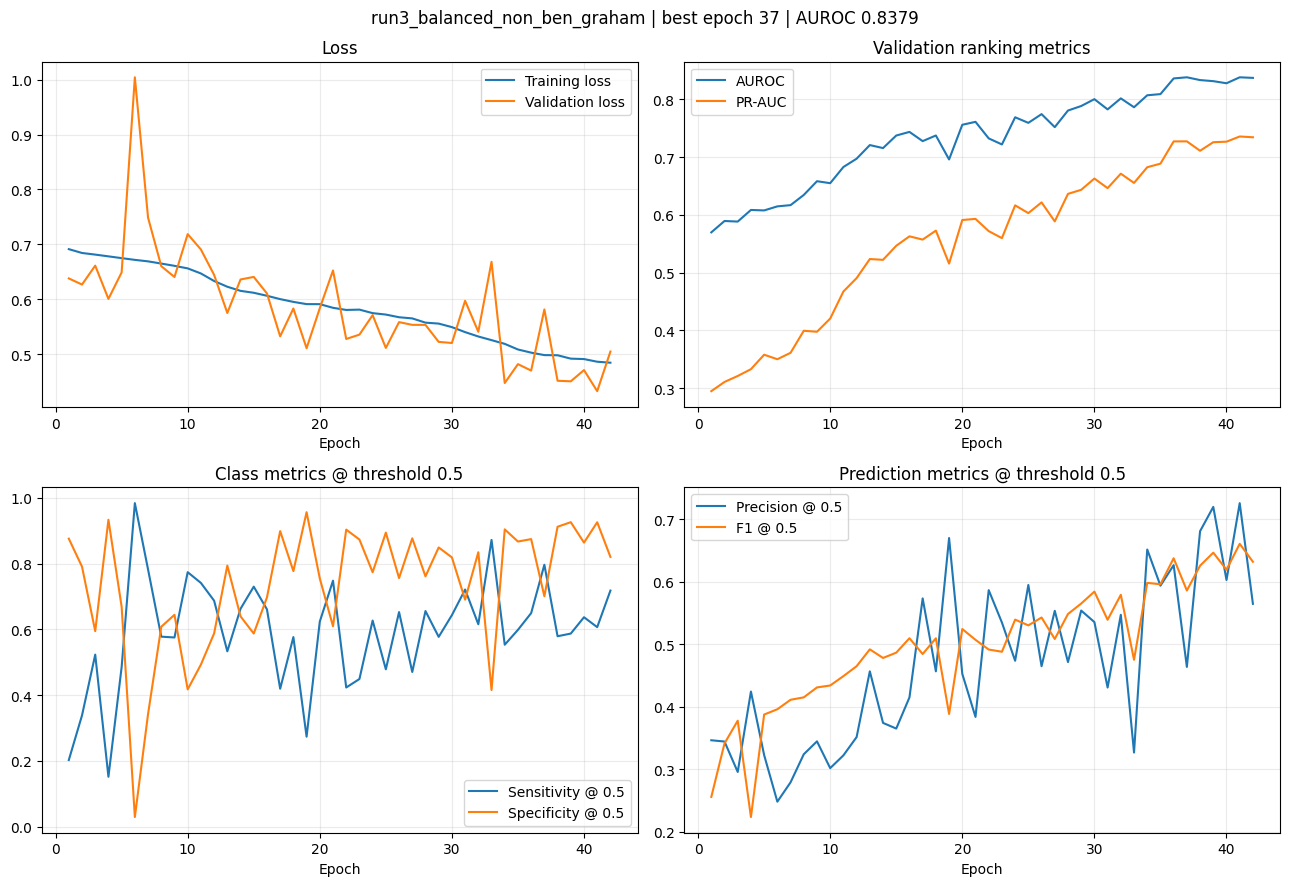

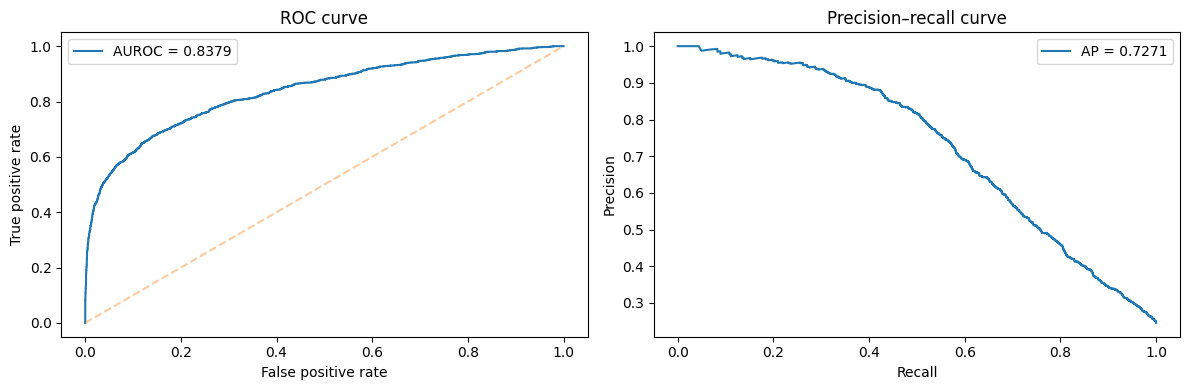

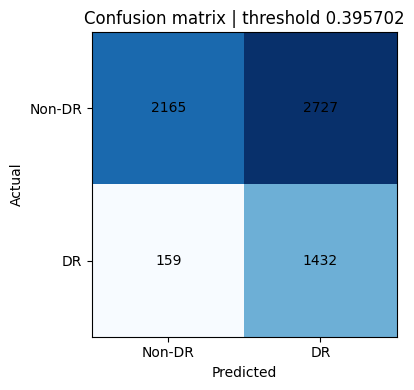


Starting: run4_imbalanced_non_ben_graham
train DR share=27.15% | imbalance detected=True | sampler=True
Batch composition: 19 non-DR, 13 DR
run4_imbalanced_non_ben_graham epoch=1 train_loss=0.6166 val_loss=3.9224 AUROC=0.5671 sens@0.5=1.0000 spec@0.5=0.0000
  sampler: {'epoch': 1, 'non_dr_draws': 40679, 'dr_draws': 27833, 'unique_dr_seen_this_epoch': 15161, 'repeated_dr_draws_augmented': 12672, 'total_unique_indices_ever': 55833}
  New best AUROC! checkpoint saved.
run4_imbalanced_non_ben_graham epoch=2 train_loss=0.0895 val_loss=3.7234 AUROC=0.5426 sens@0.5=0.9994 spec@0.5=0.0018
  sampler: {'epoch': 2, 'non_dr_draws': 40679, 'dr_draws': 27833, 'unique_dr_seen_this_epoch': 15161, 'repeated_dr_draws_augmented': 27833, 'total_unique_indices_ever': 55833}
  AUROC not improved: 1/5
run4_imbalanced_non_ben_graham epoch=3 train_loss=0.0324 val_loss=3.4883 AUROC=0.5478 sens@0.5=0.9717 spec@0.5=0.0276
  sampler: {'epoch': 3, 'non_dr_draws': 40679, 'dr_draws': 27833, 'unique_dr_seen_this_epoc

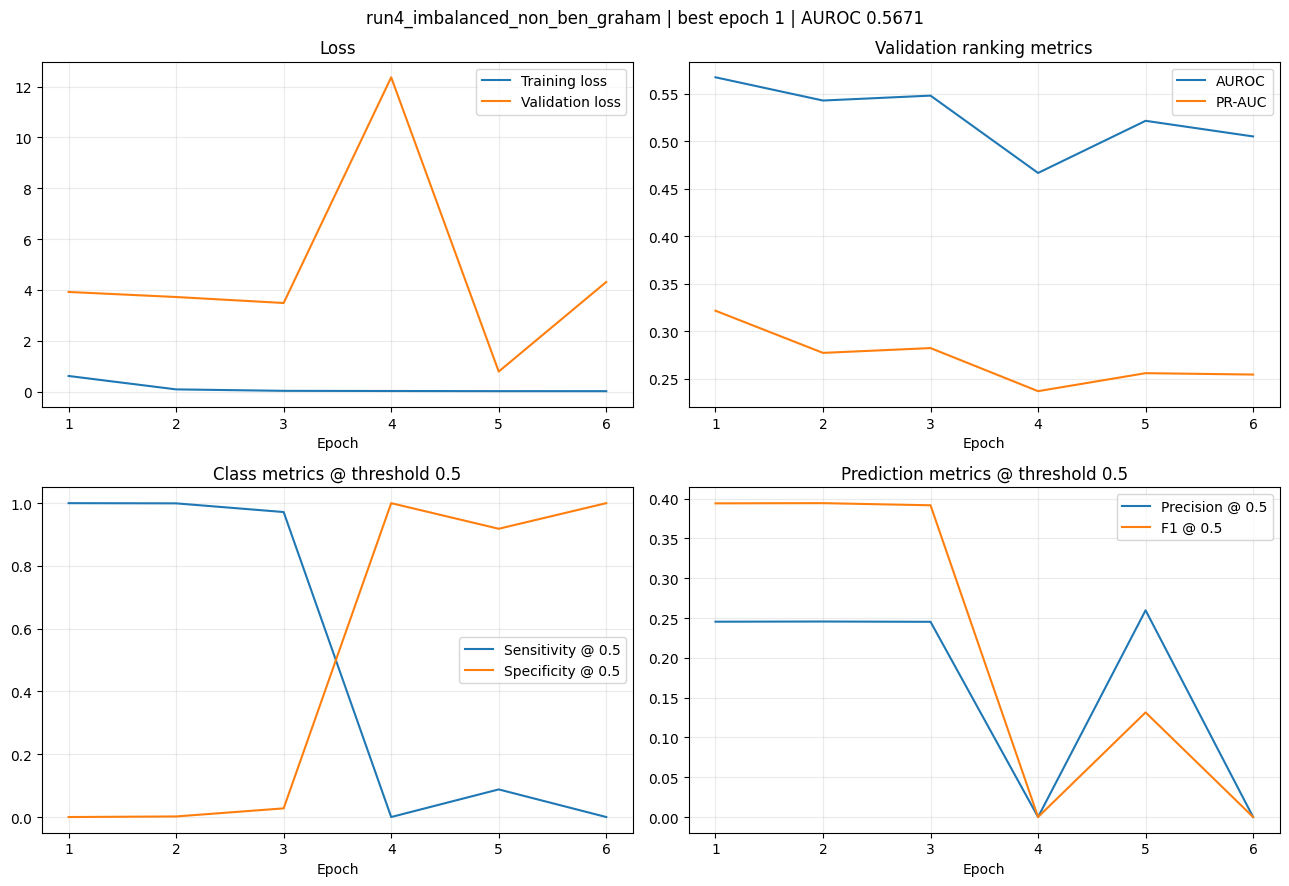

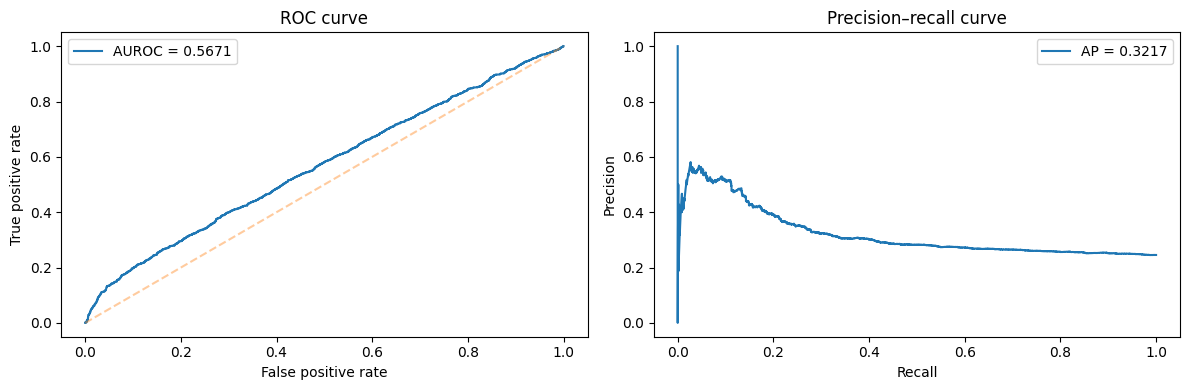

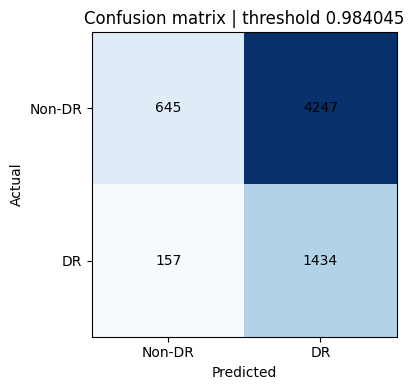

,run,best_epoch,validation_auroc,validation_pr_auc,sensitivity_at_90_target,specificity_at_90_target,threshold
0,run3_balanced_non_ben_graham,37,0.837948,0.727096,0.900063,0.442559,0.395702
1,run4_imbalanced_non_ben_graham,1,0.567064,0.321743,0.901320,0.131848,0.984045


In [8]:
results = []
if RUN_TRAINING:
    for name, frame in runs:
        assert not (WORK_ROOT / name / 'best_model.pt').exists(), f'Checkpoint already exists for {name}. Back it up before intentionally retraining.'
    for name, frame in runs:
        print('\nStarting:', name)
        summary, history, val_predictions, output = train_run(name, frame)
        save_figures(name, history, val_predictions, summary, output)
else:
    print('Training skipped; using existing run artifacts.')
for name, _ in runs:
    with open(WORK_ROOT / name / 'summary.json') as f:
        summary = json.load(f)
    results.append({'run': name, 'best_epoch': summary['best_epoch'],
                    'validation_auroc': summary['best_validation_auroc'],
                    'validation_pr_auc': summary['validation_pr_auc'],
                    'sensitivity_at_90_target': summary['at_90pct_sensitivity']['sensitivity'],
                    'specificity_at_90_target': summary['at_90pct_sensitivity']['specificity'],
                    'threshold': summary['threshold_for_90pct_sensitivity']})
validation_comparison = pd.DataFrame(results)
display(validation_comparison)
validation_comparison.to_csv(WORK_ROOT / 'comparison.csv', index=False)


## 9. Held-out test evaluation
Both checkpoints and their own validation-selected thresholds are loaded. No threshold or model selection is performed on test data. Do not use these test results to tune subsequent models.


run: run3_balanced_non_ben_graham
best_epoch: 37
test_images: 6491
test_loss: 0.6084300291554767
test_auroc: 0.8090062922891026
test_pr_auc: 0.6800602889872449
validation_selected_threshold: 0.39570239186286926
test_sensitivity: 0.8869949494949495
test_specificity: 0.4246994090075403
test_precision: 0.3323084200567644
test_f1: 0.4834824501032347
tn: 2084
fp: 2823
fn: 179
tp: 1405


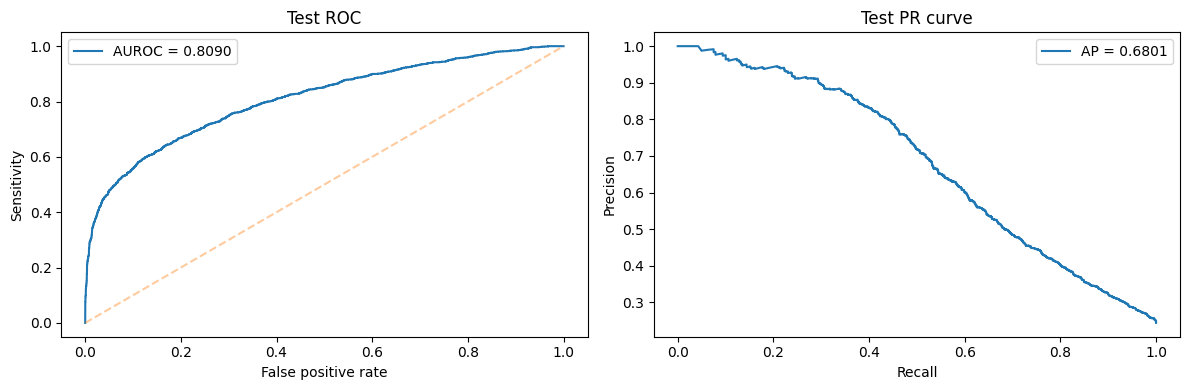

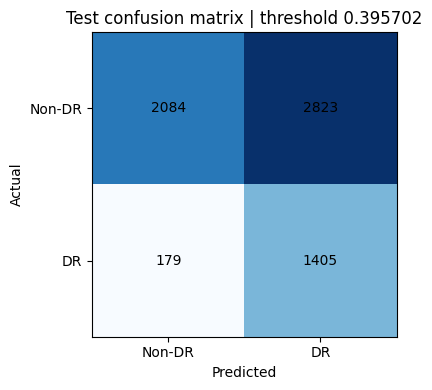


run: run4_imbalanced_non_ben_graham
best_epoch: 1
test_images: 6491
test_loss: 3.9178023571900344
test_auroc: 0.5654830735519037
test_pr_auc: 0.3242127768177925
validation_selected_threshold: 0.984045147895813
test_sensitivity: 0.9034090909090909
test_specificity: 0.14693295292439373
test_precision: 0.2547623286451843
test_f1: 0.3974447993334259
tn: 721
fp: 4186
fn: 153
tp: 1431


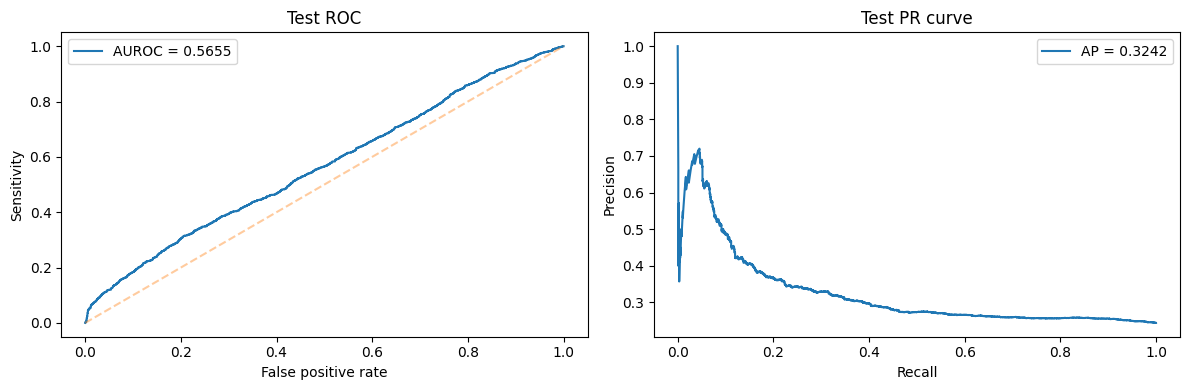

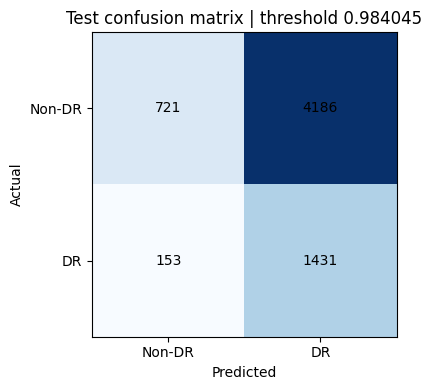

,run,best_epoch,test_images,test_loss,test_auroc,test_pr_auc,validation_selected_threshold,test_sensitivity,test_specificity,test_precision,test_f1,tn,fp,fn,tp
0,run3_balanced_non_ben_graham,37,6491,0.608430,0.809006,0.680060,0.395702,0.886995,0.424699,0.332308,0.483482,2084,2823,179,1405
1,run4_imbalanced_non_ben_graham,1,6491,3.917802,0.565483,0.324213,0.984045,0.903409,0.146933,0.254762,0.397445,721,4186,153,1431


Test evaluation completed!


In [9]:
test_results = []
if RUN_TEST:
    for run_name, frame in runs:
        run_dir = WORK_ROOT / run_name
        checkpoint = torch.load(run_dir / 'best_model.pt', map_location=device, weights_only=True)
        with open(run_dir / 'summary.json') as f:
            summary = json.load(f)
        assert checkpoint['run'] == run_name == summary['run']
        assert checkpoint['epoch'] == summary['best_epoch']
        threshold = float(summary['threshold_for_90pct_sensitivity'])
        assert np.isfinite(threshold)
        model = BaselineCNN().to(device)
        model.load_state_dict(checkpoint['model_state'])
        test_frame = frame.loc[frame.split.eq('test')].copy()
        assert len(test_frame) == 6491
        test_loader = DataLoader(RetinalDataset(test_frame, augment_repeated_dr=False),
                                 batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                                 pin_memory=torch.cuda.is_available())
        y, p, test_loss = collect_predictions(model, test_loader, nn.BCEWithLogitsLoss())
        assert len(y) == 6491 and int(y.sum()) == 1584
        assert np.isfinite(p).all()
        m = metrics_at_threshold(y, p, threshold)
        result = {'run': run_name, 'best_epoch': checkpoint['epoch'], 'test_images': len(y),
                  'test_loss': test_loss, 'test_auroc': float(roc_auc_score(y,p)),
                  'test_pr_auc': float(average_precision_score(y,p)),
                  'validation_selected_threshold': threshold,
                  **{f'test_{k}':m[k] for k in ('sensitivity','specificity','precision','f1')},
                  **{k:m[k] for k in ('tn','fp','fn','tp')}}
        test_results.append(result)
        pd.DataFrame({'y_true':y, 'probability':p, 'prediction':(p>=threshold).astype(int)}).to_csv(run_dir/'test_predictions.csv',index=False)
        pd.DataFrame([result]).to_csv(run_dir/'test_results.csv',index=False)
        print('\n' + '='*55)
        for key, value in result.items(): print(f'{key}: {value}')
        fpr,tpr,_=roc_curve(y,p); prec,rec,_=precision_recall_curve(y,p)
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        axes[0].plot(fpr,tpr,label=f"AUROC = {result['test_auroc']:.4f}")
        axes[0].plot([0,1],[0,1],'--',alpha=.4)
        axes[0].set(xlabel='False positive rate',ylabel='Sensitivity',title='Test ROC'); axes[0].legend()
        axes[1].plot(rec,prec,label=f"AP = {result['test_pr_auc']:.4f}")
        axes[1].set(xlabel='Recall',ylabel='Precision',title='Test PR curve'); axes[1].legend()
        fig.tight_layout(); fig.savefig(run_dir/'test_roc_pr_curves.png',dpi=160); plt.show(); plt.close(fig)
        cm=confusion_matrix(y,(p>=threshold).astype(int),labels=[0,1])
        fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm,cmap='Blues')
        for (i,j),num in np.ndenumerate(cm): ax.text(j,i,str(num),ha='center',va='center')
        ax.set_xticks([0,1],['Non-DR','DR']); ax.set_yticks([0,1],['Non-DR','DR'])
        ax.set(xlabel='Predicted',ylabel='Actual',title=f'Test confusion matrix | threshold {threshold:.6g}')
        fig.tight_layout(); fig.savefig(run_dir/'test_confusion_matrix.png',dpi=160); plt.show(); plt.close(fig)
        del model, test_loader, checkpoint
    test_comparison = pd.DataFrame(test_results)
    display(test_comparison)
    test_comparison.to_csv(WORK_ROOT/'test_comparison.csv',index=False)
    print('Test evaluation completed!')
else:
    print('Held-out test skipped.')


## 10. Package model artifacts
The archive contains only the experiment output directory, not the extracted retinal dataset.

In [10]:
archive = shutil.make_archive(str(WORK_ROOT), 'zip', root_dir=WORK_ROOT)
print('Saved results and ZIP:', archive)
for path in sorted(WORK_ROOT.rglob('*')):
    if path.is_file(): print(path.relative_to(WORK_ROOT))


Saved results and ZIP: /kaggle/working/oculus_plain_bce_raw.zip
comparison.csv
run3_balanced_non_ben_graham/best_model.pt
run3_balanced_non_ben_graham/best_val_predictions.csv
run3_balanced_non_ben_graham/confusion_matrix.png
run3_balanced_non_ben_graham/history.csv
run3_balanced_non_ben_graham/roc_pr_curves.png
run3_balanced_non_ben_graham/summary.json
run3_balanced_non_ben_graham/test_confusion_matrix.png
run3_balanced_non_ben_graham/test_predictions.csv
run3_balanced_non_ben_graham/test_results.csv
run3_balanced_non_ben_graham/test_roc_pr_curves.png
run3_balanced_non_ben_graham/training_metrics.png
run4_imbalanced_non_ben_graham/best_model.pt
run4_imbalanced_non_ben_graham/best_val_predictions.csv
run4_imbalanced_non_ben_graham/confusion_matrix.png
run4_imbalanced_non_ben_graham/history.csv
run4_imbalanced_non_ben_graham/roc_pr_curves.png
run4_imbalanced_non_ben_graham/sampling_counts.csv
run4_imbalanced_non_ben_graham/summary.json
run4_imbalanced_non_ben_graham/test_confusion_matri